Semanas   Ocurrencias    Prob. Simple      Prob. Acumulada   
5         145            1.45    %1.45              %
6         2029           20.29   %21.74             %
7         3504           35.04   %56.78             %
8         2553           25.53   %82.31             %
9         1160           11.60   %93.91             %
10        448            4.48    %98.39             %
11        129            1.29    %99.68             %
12        22             0.22    %99.90             %
13        9              0.09    %99.99             %
14        1              0.01    %100.00            %
📊 RESULTADOS CLAVE SIMULACIÓN MONTE CARLO
• Percentil 50 (P50 - 50% de probabilidad):  7 semanas
• Percentil 85 (P85 - 85% de probabilidad):  9 semanas
• Percentil 95 (P95 - 95% de probabilidad): 10 semanas

• Probabilidad de finalizar en <= 7 semanas: 56.78%

✅ Tabla de resultados guardada exitosamente en 'gdp_tp2_e5_resultados_monte_carlo.xlsx'


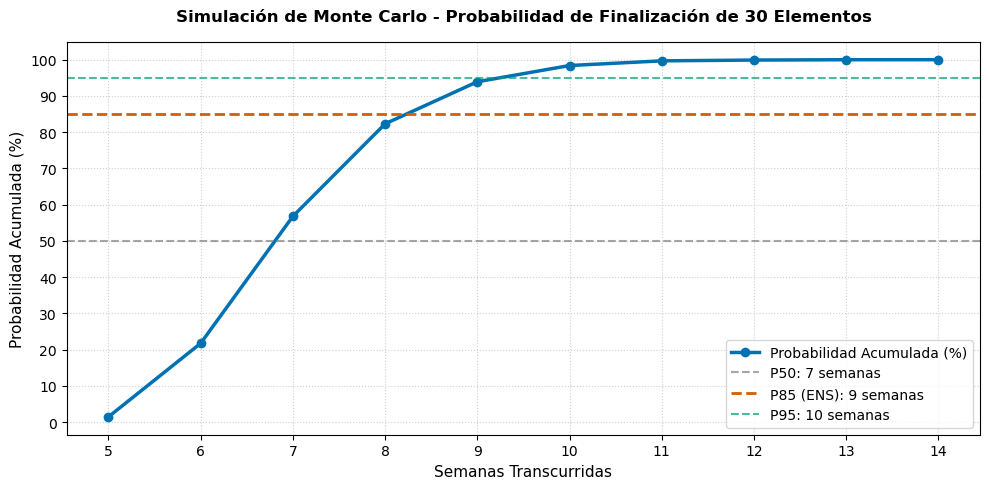

In [11]:
import random
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

# 1. DATOS DE ENTRADA (Ejercicio 5 - Guía TP2)
throughput_historico = [4, 6, 3, 5, 0, 7, 4, 5, 3, 6]  # Rendimiento semanal
backlog_pendiente = 30                                 # Tareas pendientes
iteraciones = 10000                                    # Cantidad de corridas Monte Carlo

# Semilla aleatoria para reproducibilidad exacta
random.seed(43)

# 2. EJECUCIÓN DE LA SIMULACIÓN
resultados_semanas = []

for _ in range(iteraciones):
    completados = 0
    semanas = 0
    while completados < backlog_pendiente:
        semanas += 1
        completados += random.choice(throughput_historico)
    resultados_semanas.append(semanas)

# 3. PROCESAMIENTO DE MÉTRICAS Y PERCENTILES
frecuencias = Counter(resultados_semanas)
semanas_unicas = sorted(frecuencias.keys())

prob_acumulada = 0
p50, p85, p95 = None, None, None

# Estructura de datos para exportar a Excel
tabla_datos = []

print("=" * 65)
print(f"{'Semanas':<10}{'Ocurrencias':<15}{'Prob. Simple':<18}{'Prob. Acumulada':<18}")
print("=" * 65)

for s in semanas_unicas:
    cant = frecuencias[s]
    prob_simple = (cant / iteraciones) * 100
    prob_acumulada += prob_simple
    
    if p50 is None and prob_acumulada >= 50:
        p50 = s
    if p85 is None and prob_acumulada >= 85:
        p85 = s
    if p95 is None and prob_acumulada >= 95:
        p95 = s
        
    print(f"{s:<10}{cant:<15}{prob_simple:<8.2f}%{prob_acumulada:<18.2f}%")
    
    tabla_datos.append({
        'Semanas': s,
        'Ocurrencias': cant,
        'Prob. Simple (%)': round(prob_simple, 2),
        'Prob. Acumulada (%)': round(prob_acumulada, 2)
    })

print("=" * 65)
print("📊 RESULTADOS CLAVE SIMULACIÓN MONTE CARLO")
print("=" * 65)
print(f"• Percentil 50 (P50 - 50% de probabilidad):  {p50} semanas")
print(f"• Percentil 85 (P85 - 85% de probabilidad):  {p85} semanas")
print(f"• Percentil 95 (P95 - 95% de probabilidad): {p95} semanas")

prob_7_semanas = sum(frecuencias[s] for s in semanas_unicas if s <= 7) / iteraciones * 100
print(f"\n• Probabilidad de finalizar en <= 7 semanas: {prob_7_semanas:.2f}%")

# --- EXPORTAR A EXCEL ---
df_resultados = pd.DataFrame(tabla_datos)
df_resultados.to_excel("gdp_tp2_e5_resultados_monte_carlo.xlsx", index=False)
print("\n✅ Tabla de resultados guardada exitosamente en 'gdp_tp2_e5_resultados_monte_carlo.xlsx'")

# 4. GRÁFICO DE LA DISTRIBUCIÓN
x_semanas = semanas_unicas
y_acumulada = [d['Prob. Acumulada (%)'] for d in tabla_datos]

plt.figure(figsize=(10, 5), dpi=100)
plt.plot(x_semanas, y_acumulada, marker='o', color='#0072B2', linewidth=2.5, label='Probabilidad Acumulada (%)')

plt.axhline(50, color='gray', linestyle='--', alpha=0.7, label=f'P50: {p50} semanas')
plt.axhline(85, color='#D55E00', linestyle='--', linewidth=2, label=f'P85 (ENS): {p85} semanas')
plt.axhline(95, color='#009E73', linestyle='--', alpha=0.7, label=f'P95: {p95} semanas')

plt.title('Simulación de Monte Carlo - Probabilidad de Finalización de 30 Elementos', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Semanas Transcurridas', fontsize=11)
plt.ylabel('Probabilidad Acumulada (%)', fontsize=11)
plt.xticks(x_semanas)
plt.yticks(range(0, 101, 10))
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower right')

plt.tight_layout()
plt.show()